# Exploratory data analysis — F1 tyre strategy

Basic exploratory data analysis for the F1 tyre strategy task.

Target: `next_compound` (SOFT / MEDIUM / HARD / WET_OR_INTER / NONE), i.e. the compound of
the driver's next stint, or NONE when there is no further pit stop.

Run top to bottom. Every chart is shown inline and also saved in `eda_plots/`.

## Setup
Imports, class order/colours and plotting helpers.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from data import load_data

OUT = Path("eda_plots")
OUT.mkdir(exist_ok=True)

TARGET = "next_compound"
CLASSES = ["SOFT", "MEDIUM", "HARD", "WET_OR_INTER", "NONE"]
# One fixed colour per class, used in every chart.
CLASS_COLORS = {
    "SOFT": "#eb6834",
    "MEDIUM": "#eda100",
    "HARD": "#2a78d6",
    "WET_OR_INTER": "#1baf7a",
    "NONE": "#8c8c8c",
}

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
})


def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    plt.show()
    print(f"  saved {OUT / name}.png")


def section(title):
    print(f"\n{'=' * 70}\n{title}\n{'=' * 70}")


def stacked_share(ax, table, title, xlabel):
    """Stacked bar of class shares; `table` = rows are groups, columns are classes."""
    share = table.reindex(columns=CLASSES, fill_value=0)
    share = share.div(share.sum(axis=1), axis=0)
    bottom = np.zeros(len(share))
    x = np.arange(len(share))
    for cls in CLASSES:
        ax.bar(x, share[cls], bottom=bottom, color=CLASS_COLORS[cls], label=cls,
               edgecolor="white", linewidth=1)
        bottom += share[cls].to_numpy()
    ax.set_xticks(x, share.index.astype(str), rotation=45, ha="right")
    ax.set_ylabel("share of laps")
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)

/Users/edouarddewaerheijd/unige/Formula-1-Tyre-Strategy/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load

In [2]:
train, test, sample_submission = load_data()
train["driver_race"] = train["race_id"] + "_" + train["driver_code"]
test["driver_race"] = test["race_id"] + "_" + test["driver_code"]

section("Shapes")
print(f"train: {train.shape}   test: {test.shape}   sample_submission: {sample_submission.shape}")
print(f"train races: {train.race_id.nunique()}   test races: {test.race_id.nunique()}   "
      f"shared races: {len(set(train.race_id) & set(test.race_id))}")
print(f"train driver-races: {train.driver_race.nunique()}   "
      f"test driver-races: {test.driver_race.nunique()}   submission rows: {len(sample_submission)}")


Shapes
train: (104757, 73)   test: (40901, 72)   sample_submission: (1740, 6)
train races: 95   test races: 92   shared races: 0
train driver-races: 1916   test driver-races: 1814   submission rows: 1740


**Results.**
- train: 104,757 laps × 73 cols, 95 races, 1,916 driver-races. test: 40,901 laps, 92 races, 1,814 driver-races.
- **Zero races are shared** between train and test → grouping CV folds by race (`year` × `round`) reproduces the real split exactly.
- Submission has **1,740 rows < 1,814 test driver-races**: ~74 test driver-races are not scored (likely retirements before the cutoff). Check which ones are missing in `sample_submission` before building the prediction table.
- Effective sample size is ~1,900 driver-races, not ~100k laps.

## 1. Target distribution


1. Target distribution
               count  share
next_compound              
NONE           44251  0.422
HARD           25846  0.247
MEDIUM         16888  0.161
SOFT           12197  0.116
<NA>            3566  0.034
WET_OR_INTER    2009  0.019

Missing target: 3566 laps (result_status of these: {'Retired': 1376, 'Collision damage': 330, 'Disqualified': 330, 'Collision': 271, 'Engine': 224})


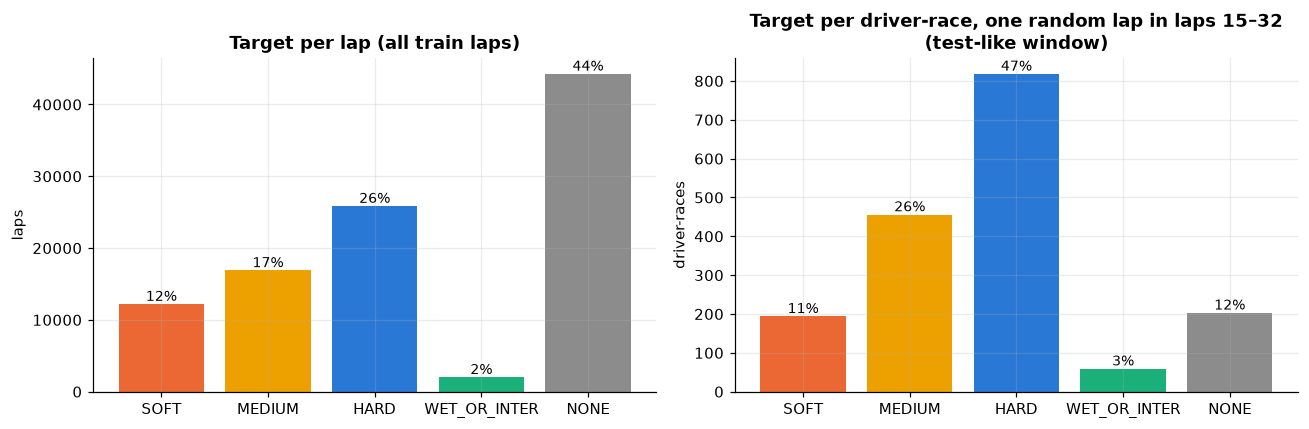

  saved eda_plots/01_target_distribution.png

Class shares in test-like window (one lap per driver-race):
next_compound
SOFT            0.112
MEDIUM          0.264
HARD            0.473
WET_OR_INTER    0.034
NONE            0.117


In [3]:
section("1. Target distribution")
counts = train[TARGET].value_counts(dropna=False)
print(pd.DataFrame({"count": counts, "share": (counts / len(train)).round(3)}))
print(f"\nMissing target: {train[TARGET].isna().sum()} laps "
      f"(result_status of these: {train.loc[train[TARGET].isna(), 'result_status'].value_counts().head(5).to_dict()})")

labelled = train[train[TARGET].notna()].copy()
labelled[TARGET] = labelled[TARGET].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
lap_counts = labelled[TARGET].value_counts().reindex(CLASSES)
axes[0].bar(lap_counts.index, lap_counts.values, color=[CLASS_COLORS[c] for c in CLASSES])
axes[0].set_title("Target per lap (all train laps)")
axes[0].set_ylabel("laps")
for i, v in enumerate(lap_counts.values):
    axes[0].text(i, v, f"{v / lap_counts.sum():.0%}", ha="center", va="bottom", fontsize=9)

# The test set is scored once per driver-race, so the per-lap view over-weights long stints.
# Look at the target on the last observed lap of each driver in a test-like window.
last_lap_test = test.groupby("driver_race")["lap_number"].max()
lo, hi = last_lap_test.quantile([0.05, 0.95])
window = labelled[labelled.lap_number.between(lo, hi)]
per_driver = window.groupby("driver_race")[TARGET].agg(lambda s: s.sample(1, random_state=0).iloc[0])
dr_counts = per_driver.value_counts().reindex(CLASSES, fill_value=0)
axes[1].bar(dr_counts.index, dr_counts.values, color=[CLASS_COLORS[c] for c in CLASSES])
axes[1].set_title(f"Target per driver-race, one random lap in laps {lo:.0f}–{hi:.0f}\n(test-like window)")
axes[1].set_ylabel("driver-races")
for i, v in enumerate(dr_counts.values):
    axes[1].text(i, v, f"{v / dr_counts.sum():.0%}", ha="center", va="bottom", fontsize=9)
save(fig, "01_target_distribution")
print("\nClass shares in test-like window (one lap per driver-race):")
print((dr_counts / dr_counts.sum()).round(3).to_string())

**Results.**
- All train laps: NONE 42%, HARD 25%, MEDIUM 16%, SOFT 12%, WET/INTER 2%, plus **3.4% missing target** (3,566 laps), almost all from drivers who did not finish (Retired, collisions, DSQ, engine). Drop these laps from training — they have no defined label.
- Test-like window (one random lap per driver-race in the 5–95% range of test cutoff laps): **HARD 47%, MEDIUM 26%, NONE 12%, SOFT 11%, WET/INTER 3%**.
- The priors flip completely (NONE 42% → 12%, HARD 25% → 47%). A model trained on all laps unweighted will massively over-predict NONE → restrict/reweight training laps to the test window and evaluate on that window only.

## 2. Train vs test: where are the laps?


2. Train vs test lap coverage
Laps observed per test driver-race:
count    1814.0
mean       22.5
std         5.6
min         1.0
25%        19.0
50%        23.0
75%        26.0
max        36.0


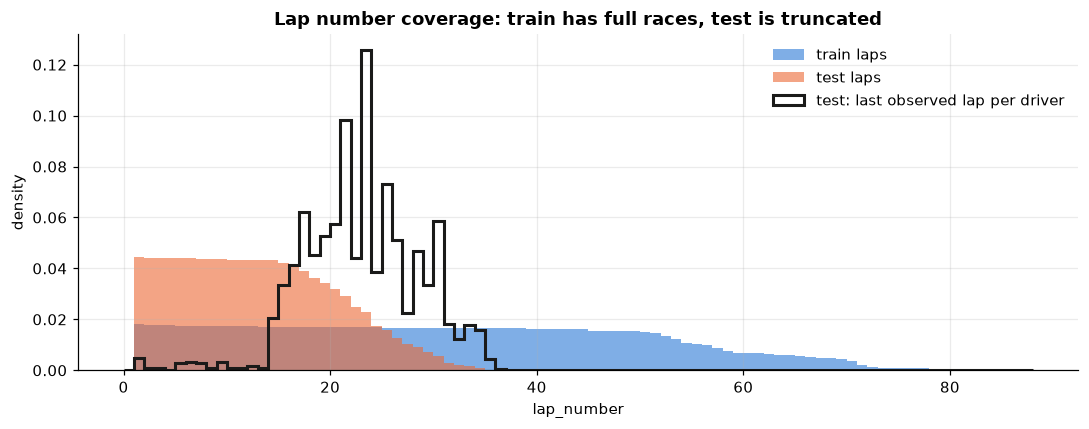

  saved eda_plots/02_train_vs_test_lap_coverage.png


In [4]:
section("2. Train vs test lap coverage")
print("Laps observed per test driver-race:")
print(test.groupby("driver_race").size().describe().round(1).to_string())
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.arange(0, train.lap_number.max() + 2)
ax.hist(train.lap_number, bins=bins, alpha=0.6, density=True, label="train laps", color="#2a78d6")
ax.hist(test.lap_number, bins=bins, alpha=0.6, density=True, label="test laps", color="#eb6834")
ax.hist(last_lap_test, bins=bins, histtype="step", linewidth=2, density=True,
        label="test: last observed lap per driver", color="#1a1a19")
ax.set_title("Lap number coverage: train has full races, test is truncated")
ax.set_xlabel("lap_number")
ax.set_ylabel("density")
ax.legend(frameon=False)
save(fig, "02_train_vs_test_lap_coverage")

**Results.**
- Test driver-races contain 1–36 laps (median 23, IQR 19–26): test races are cut off roughly in the first third to half of the race, while train covers full races.
- The prediction is made at the **last observed lap** of each test driver, so validation must score one lap per driver-race drawn from this cutoff distribution.
- A few test drivers have very few laps (min = 1) → features based on lap history must handle short histories.

## 3. Target vs race progress


3. Target vs race progress


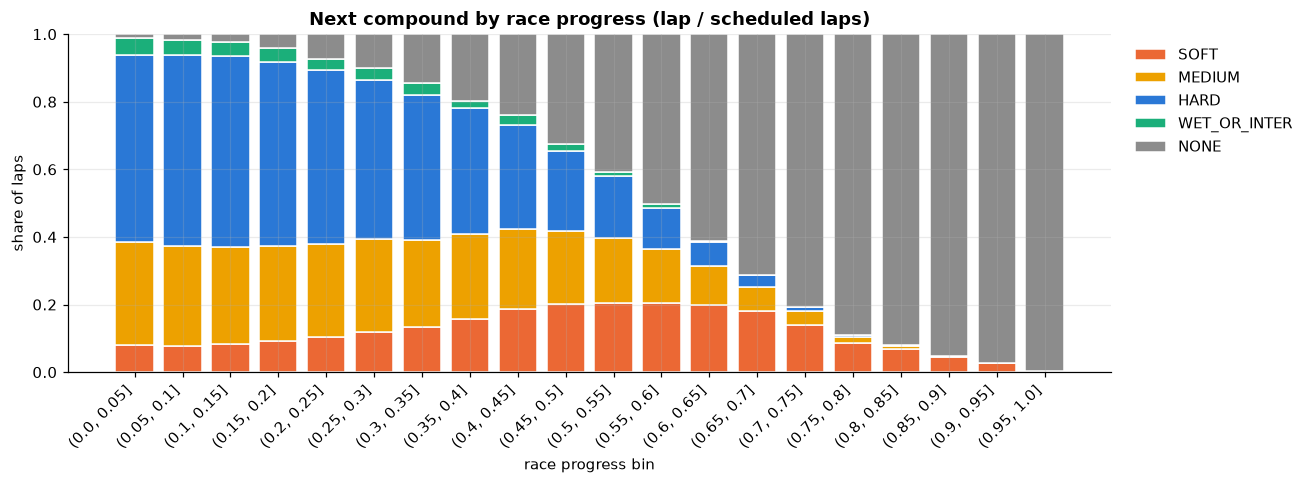

  saved eda_plots/03_target_by_race_progress.png


In [5]:
section("3. Target vs race progress")
labelled["race_progress"] = labelled["lap_number"] / labelled["scheduled_laps"]
labelled["progress_bin"] = pd.cut(labelled["race_progress"], bins=np.linspace(0, 1.05, 22)).astype(str)
fig, ax = plt.subplots(figsize=(12, 4.5))
stacked_share(ax, pd.crosstab(labelled["progress_bin"], labelled[TARGET]).sort_index(
    key=lambda idx: idx.str.extract(r"\(([-\d.]+)")[0].astype(float)),
    "Next compound by race progress (lap / scheduled laps)", "race progress bin")
save(fig, "03_target_by_race_progress")

**Results.**
- Race progress is the dominant signal for NONE: ~1% NONE at the start, ~50% at mid-race, ~100% in the last 10%.
- Early in the race HARD (~55%) and MEDIUM (~30%) dominate; SOFT grows towards mid-race (~20% at 0.45–0.65), i.e. late-race sprints on softs.
- WET/INTER is concentrated early (first ~35% of laps).
- In the test window (race progress ≈ 0.2–0.5) all five classes are present, so the problem there is genuinely multiclass, not just "stop or not".

## 4. Current compound and stint vs next compound


4. Current compound / stint vs target
Row-normalised P(next_compound | current compound):
next_compound  SOFT  MEDIUM  HARD  WET_OR_INTER  NONE
compound                                             
HARD           0.12    0.17  0.11          0.00  0.60
INTERMEDIATE   0.14    0.42  0.03          0.30  0.12
MEDIUM         0.13    0.07  0.48          0.01  0.30
SOFT           0.10    0.32  0.19          0.00  0.39
WET            0.07    0.06  0.00          0.87  0.00


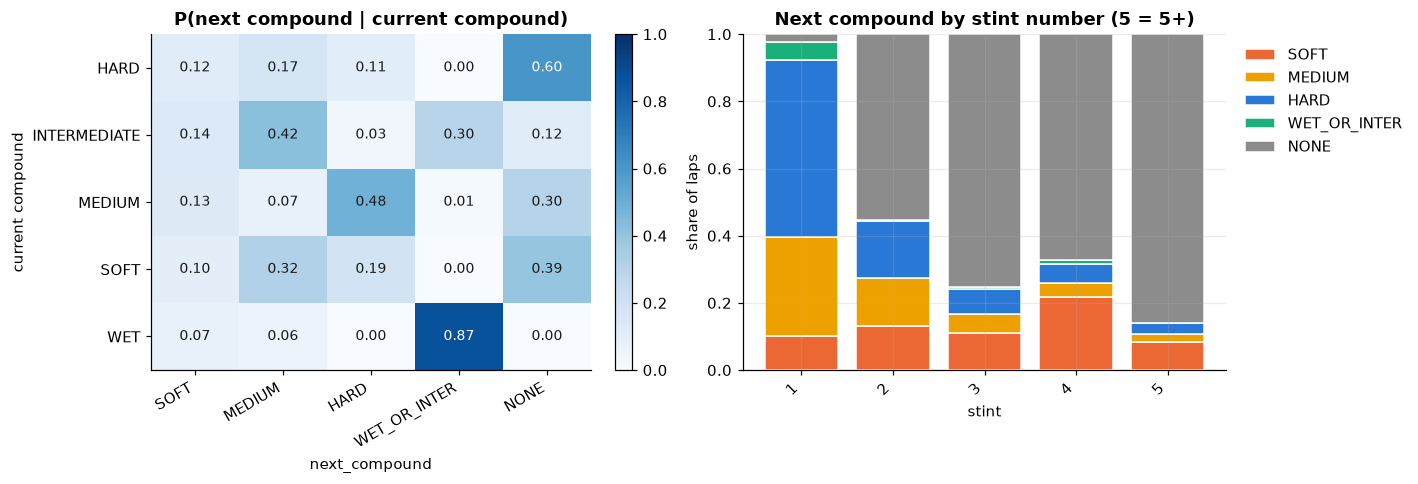

  saved eda_plots/04_target_by_current_compound_and_stint.png


In [6]:
section("4. Current compound / stint vs target")
ct = pd.crosstab(labelled["compound"].astype(str), labelled[TARGET], normalize="index").reindex(columns=CLASSES)
print("Row-normalised P(next_compound | current compound):")
print(ct.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
im = axes[0].imshow(ct.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
axes[0].set_xticks(range(len(CLASSES)), CLASSES, rotation=30, ha="right")
axes[0].set_yticks(range(len(ct)), ct.index)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        v = ct.iat[i, j]
        axes[0].text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                     color="white" if v > 0.5 else "#1a1a19")
axes[0].set_title("P(next compound | current compound)")
axes[0].set_xlabel("next_compound")
axes[0].set_ylabel("current compound")
axes[0].grid(False)
fig.colorbar(im, ax=axes[0], fraction=0.04)

stacked_share(axes[1], pd.crosstab(labelled["stint"].clip(upper=5), labelled[TARGET]),
              "Next compound by stint number (5 = 5+)", "stint")
save(fig, "04_target_by_current_compound_and_stint")

**Results.**
- Clear transition structure: **MEDIUM → HARD 0.48**, **SOFT → MEDIUM 0.32**, **WET → WET/INTER 0.87**, INTER → MEDIUM 0.42 (drying track) / WET/INTER 0.30. HARD → NONE 0.60 (HARD is usually the last stint).
- Same-compound transitions are rare (MEDIUM→MEDIUM 0.07, HARD→HARD 0.11): reflects the two-dry-compound rule → "compounds used so far" is a key engineered feature.
- Stint 1 → mostly HARD/MEDIUM (~90% stop again); stint ≥ 2 → mostly NONE (55% at stint 2, ~75% at stint 3+).
- Note: these are per-lap shares over the whole race, so they mix with race progress — a transition-matrix baseline should be estimated on the test window only.

## 5. Target over seasons and circuits


5. Target over years and circuits


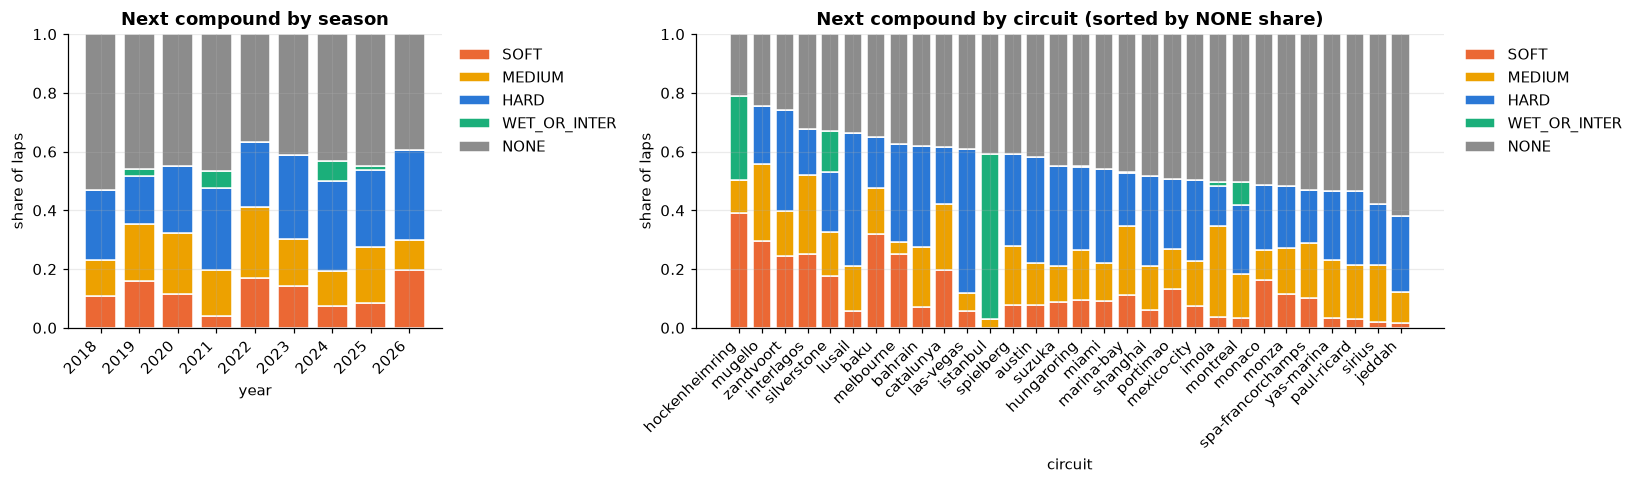

  saved eda_plots/05_target_by_year_and_circuit.png


In [7]:
section("5. Target over years and circuits")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 2]})
stacked_share(axes[0], pd.crosstab(labelled["year"], labelled[TARGET]), "Next compound by season", "year")
by_circuit = pd.crosstab(labelled["circuit_id"], labelled[TARGET])
by_circuit = by_circuit.loc[(by_circuit.div(by_circuit.sum(axis=1), axis=0)).get("NONE", 0).sort_values().index]
stacked_share(axes[1], by_circuit, "Next compound by circuit (sorted by NONE share)", "circuit")
save(fig, "05_target_by_year_and_circuit")

**Results.**
- Seasons: moderate variation (NONE ≈ 40–55%; SOFT almost absent in 2021, larger in 2022/2026; wet seasons 2021 & 2024). Year effects partly reflect regulation/compound-allocation changes.
- Circuits: strong effects. Istanbul (~55% WET/INTER) and Hockenheimring (~30%) are wet races; Silverstone and Montreal also have some wet laps. Jeddah (~62% NONE), Sirius, Paul Ricard, Yas Marina and Spa have the highest NONE share (one-stop circuits). Las Vegas/Lusail are heavily HARD; Mugello/Zandvoort/Baku have lots of SOFT.
- Circuit is useful but each circuit has only a handful of races → target-encode with strong smoothing (inside CV folds only) or use circuit-level physical features (`hardness_scale`, track length) instead of a raw ID.

## 6. Key numeric features by target class


6. Numeric features by target
               tyre_life_laps  laps_remaining  race_progress  position  track_temp_c  air_temp_c  humidity_pct  gap_to_car_ahead_s
next_compound                                                                                                                     
SOFT                     13.0            32.0           0.49      12.0          35.8        22.0          56.2                3.12
MEDIUM                   12.0            43.0           0.28      10.0          34.3        22.9          56.7                1.89
HARD                     11.0            46.0           0.23       8.0          36.2        22.8          52.8                1.80
WET_OR_INTER             11.0            45.0           0.23       9.0          24.1        16.3          79.0                1.93
NONE                     16.0            14.0           0.76       9.0          34.4        23.0          53.5                3.48


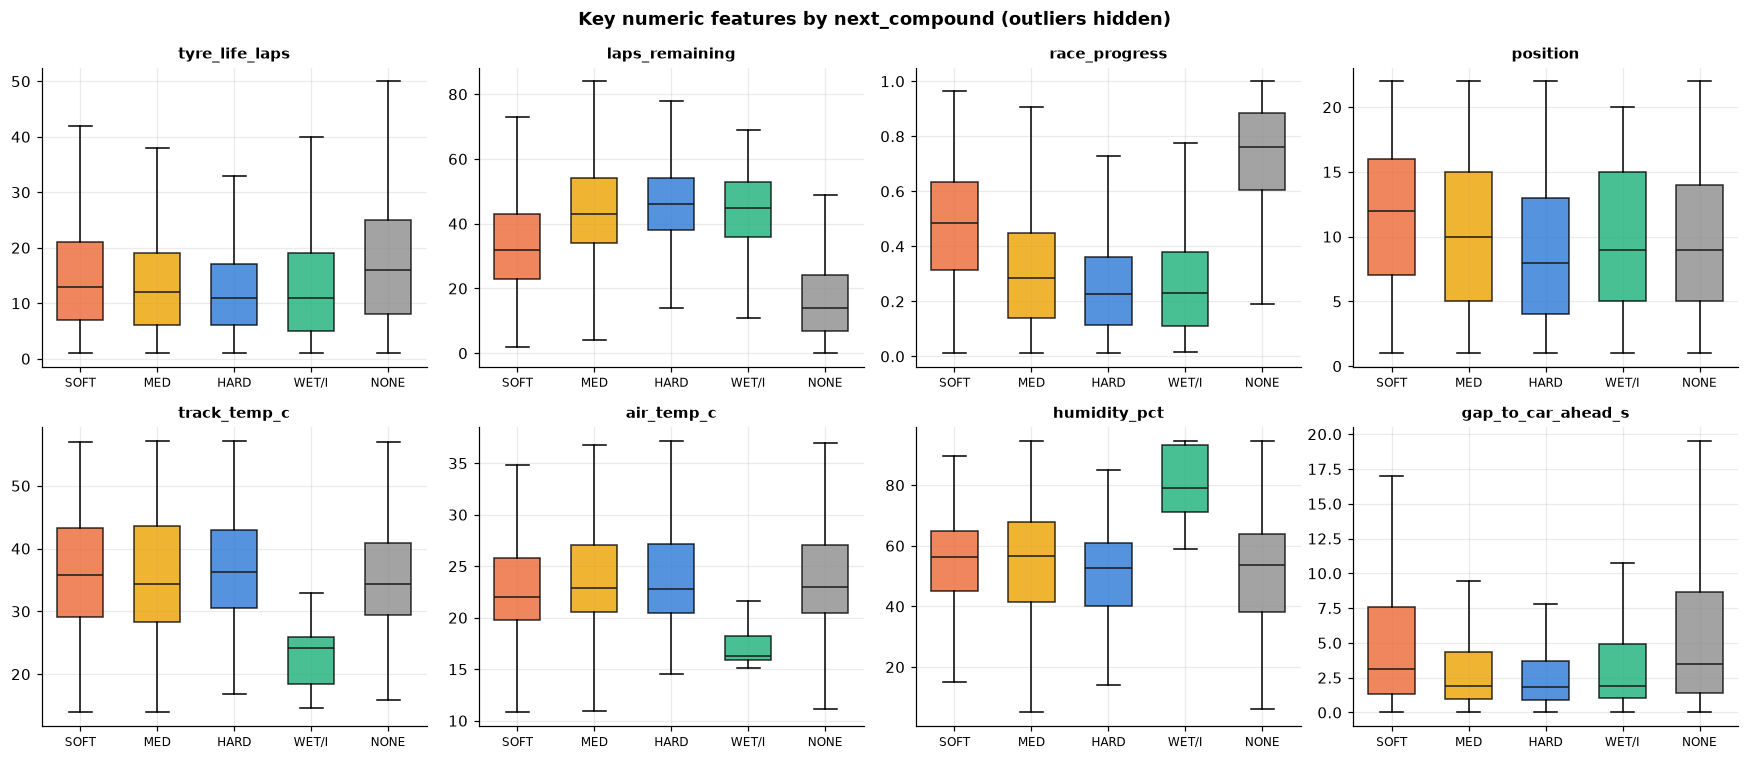

  saved eda_plots/06_numeric_features_by_target.png


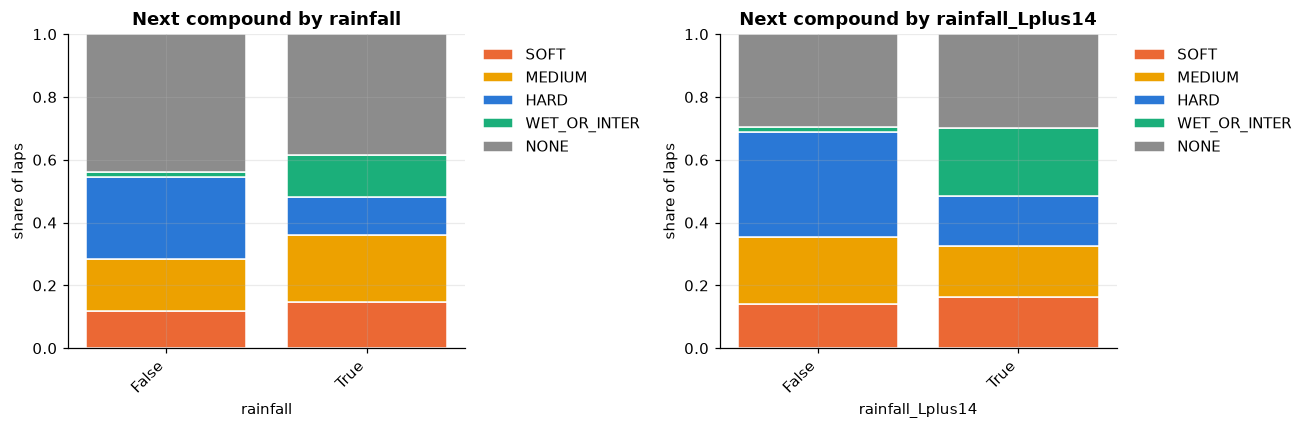

  saved eda_plots/07_target_by_rainfall.png


In [8]:
section("6. Numeric features by target")
key_feats = ["tyre_life_laps", "laps_remaining", "race_progress", "position",
             "track_temp_c", "air_temp_c", "humidity_pct", "gap_to_car_ahead_s"]
print(labelled.groupby(TARGET)[key_feats].median().reindex(CLASSES).round(2).to_string())

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, feat in zip(axes.flat, key_feats):
    data = [labelled.loc[labelled[TARGET] == c, feat].dropna().astype(float) for c in CLASSES]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.6)
    for patch, cls in zip(bp["boxes"], CLASSES):
        patch.set_facecolor(CLASS_COLORS[cls])
        patch.set_alpha(0.8)
    for med in bp["medians"]:
        med.set_color("#1a1a19")
    ax.set_xticks(range(1, len(CLASSES) + 1), ["SOFT", "MED", "HARD", "WET/I", "NONE"], fontsize=8)
    ax.set_title(feat, fontsize=10)
fig.suptitle("Key numeric features by next_compound (outliers hidden)", fontweight="bold")
save(fig, "06_numeric_features_by_target")

# Weather: does rain now / in 14 laps predict a switch to wets?
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["rainfall", "rainfall_Lplus14"]):
    stacked_share(ax, pd.crosstab(labelled[col].astype(str), labelled[TARGET]),
                  f"Next compound by {col}", col)
save(fig, "07_target_by_rainfall")

**Results (medians).**
| class | tyre_life | laps_remaining | race_progress | track °C | air °C | humidity % |
|---|---|---|---|---|---|---|
| SOFT | 13 | 32 | 0.49 | 35.8 | 22.0 | 56 |
| MEDIUM | 12 | 43 | 0.28 | 34.3 | 22.9 | 57 |
| HARD | 11 | 46 | 0.23 | 36.2 | 22.8 | 53 |
| WET/INTER | 11 | 45 | 0.23 | **24.1** | **16.3** | **79** |
| NONE | 16 | **14** | **0.76** | 34.4 | 23.0 | 54 |

- `laps_remaining`/`race_progress` separate NONE from the rest; they also separate SOFT (later, fewer laps left) from MEDIUM/HARD.
- Weather separates WET/INTER: ~12 °C cooler track, ~6 °C cooler air, +25 pp humidity.
- `position` / gaps differ little between classes (SOFT drivers sit slightly further back, median P12).

**Rainfall plot.** When `rainfall_Lplus14` is True, WET/INTER jumps from ~1% to ~22% of laps and HARD drops; current `rainfall` is a weaker signal (~13%). Rain 14 laps ahead is more informative than rain now — but it is a *future* value: confirm it is a legitimate feature at test time (it is present in test with ~0.4% missing, so it seems to be provided).

## 7. Feature–target association (one-vs-rest correlation per class)


7. Feature-target correlation (one-vs-rest)
Top 25 features by max |corr| with any class:
                               SOFT  MEDIUM   HARD  WET_OR_INTER   NONE
race_progress                -0.032  -0.297 -0.501        -0.120  0.719
laps_remaining                0.038   0.296  0.475         0.103 -0.694
lap_number                   -0.022  -0.283 -0.477        -0.120  0.681
race_time_s                  -0.014  -0.280 -0.482        -0.123  0.678
stint                         0.034  -0.233 -0.365        -0.116  0.506
rainfall_Lplus14              0.014  -0.027 -0.078         0.269  0.001
laps_down                     0.037  -0.103 -0.191        -0.037  0.231
humidity_pct                  0.025   0.044 -0.072         0.226 -0.049
track_temp_c                  0.024   0.014  0.061        -0.210 -0.020
tyre_life_laps               -0.005  -0.074 -0.160        -0.033  0.209
gap_to_leader_s               0.070  -0.084 -0.199        -0.031  0.201
air_temp_c                   -0.039   0.011  

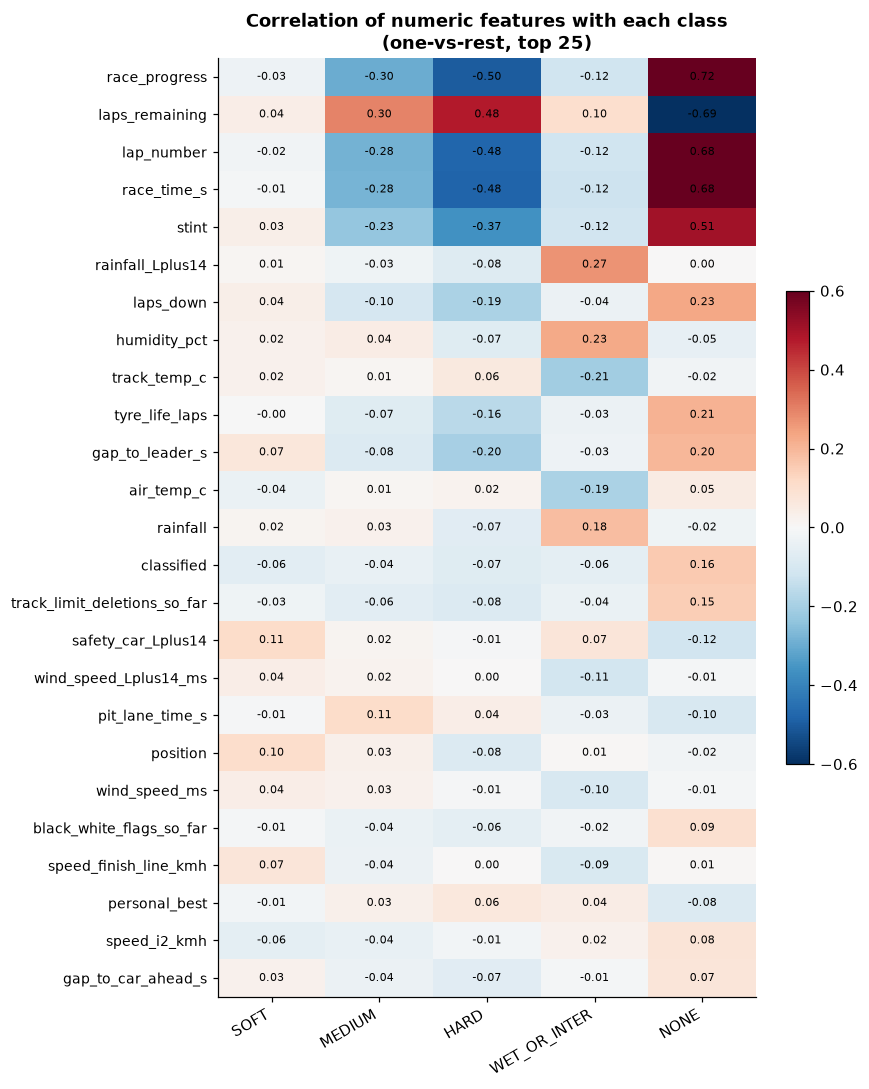

  saved eda_plots/08_feature_target_correlation.png


In [9]:
section("7. Feature-target correlation (one-vs-rest)")
num = labelled.select_dtypes(include=["number", "bool", "boolean"]).astype(float)
num = num.loc[:, num.nunique() > 1]
onehot = pd.get_dummies(labelled[TARGET]).reindex(columns=CLASSES).astype(float)
assoc = pd.DataFrame({c: num.corrwith(onehot[c]) for c in CLASSES})
assoc = assoc.loc[assoc.abs().max(axis=1).sort_values(ascending=False).index]
top = assoc.head(25)
print("Top 25 features by max |corr| with any class:")
print(top.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 10))
im = ax.imshow(top.to_numpy(), cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto")
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=30, ha="right")
ax.set_yticks(range(len(top)), top.index, fontsize=9)
for i in range(top.shape[0]):
    for j in range(top.shape[1]):
        ax.text(j, i, f"{top.iat[i, j]:.2f}", ha="center", va="center", fontsize=7.5)
ax.set_title("Correlation of numeric features with each class\n(one-vs-rest, top 25)")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.04)
save(fig, "08_feature_target_correlation")

**Results.**
- NONE is by far the most predictable class linearly: `race_progress` 0.72, `laps_remaining` −0.69, `lap_number` 0.68, `race_time_s` 0.68, `stint` 0.51.
- HARD is the mirror image (race_progress −0.50, laps_remaining 0.48, stint −0.37).
- WET/INTER: `rainfall_Lplus14` 0.27, `humidity_pct` 0.23, `track_temp_c` −0.21, `air_temp_c` −0.19, `rainfall` 0.18.
- **SOFT and MEDIUM have no feature with |r| > 0.12** (SOFT: `safety_car_Lplus14` 0.11, `position` 0.10). They are not linearly separable from single features → need interactions (current compound × stint × progress), which favours tree models.
- Caveat: these correlations are over all laps, so they are dominated by the NONE vs rest contrast; within the test window they will be much weaker.

## 8. Feature–feature correlation (redundancy)


8. Feature-feature correlation
Highly correlated pairs (|r| > 0.9): 6  -> candidates to drop/merge
          level_0               level_1   corr
    pressure_mbar pressure_Lplus14_mbar  1.000
circuit_length_km        scheduled_laps -0.985
       lap_number         race_progress  0.957
   laps_remaining         race_progress -0.957
      race_time_s         race_progress  0.931
       lap_number           race_time_s  0.919


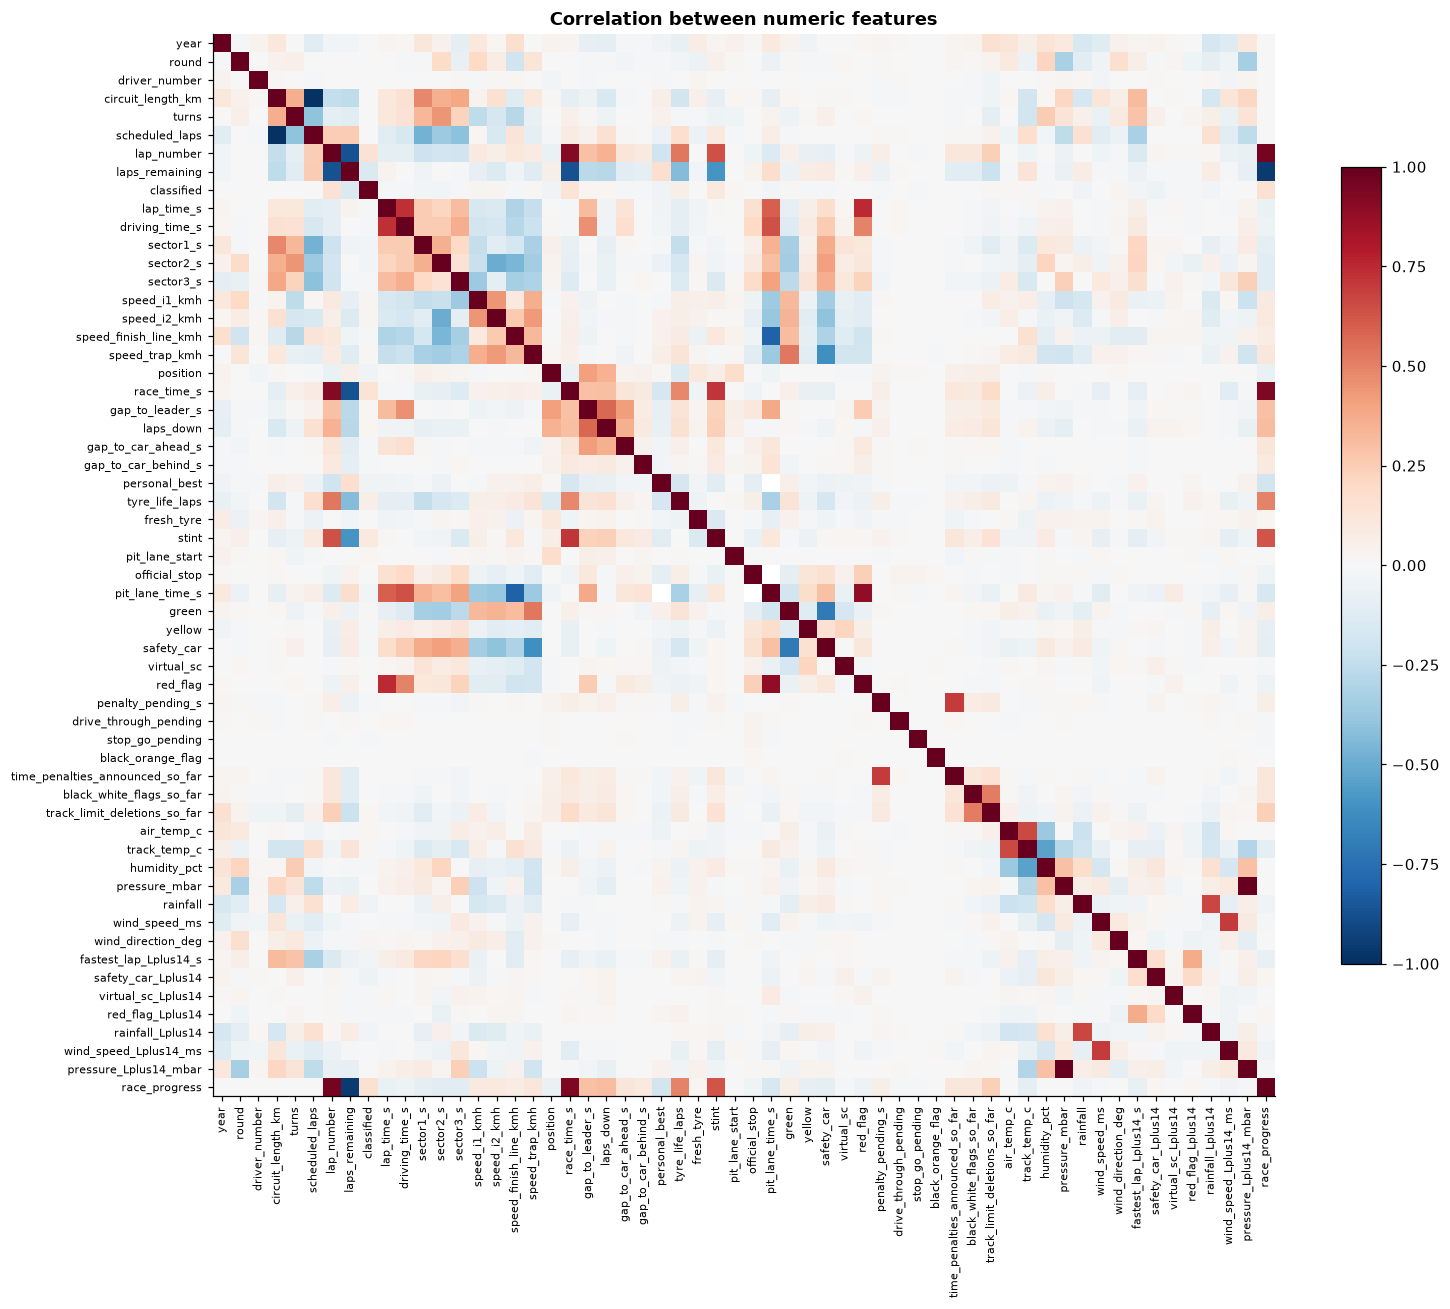

  saved eda_plots/09_feature_correlation_matrix.png


In [10]:
section("8. Feature-feature correlation")
corr = num.corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("corr").reset_index())
pairs = pairs.loc[pairs["corr"].abs() > 0.9].sort_values("corr", key=abs, ascending=False)
print(f"Highly correlated pairs (|r| > 0.9): {len(pairs)}  -> candidates to drop/merge")
print(pairs.head(30).round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(corr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=7)
ax.set_title("Correlation between numeric features")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.03)
save(fig, "09_feature_correlation_matrix")

**Results.** 6 pairs with |r| > 0.9:
- `pressure_mbar` ↔ `pressure_Lplus14_mbar` (1.00) → keep one.
- `circuit_length_km` ↔ `scheduled_laps` (−0.985) → race distance is fixed (~305 km), keep one.
- `lap_number`, `race_time_s`, `race_progress`, `laps_remaining` form one collinear block (|r| 0.92–0.96) → for linear models / NB keep only `race_progress` (+ `laps_remaining`); tree models can keep them.

## 9. Missing values


9. Missing values
                                 train   test
stint                            0.000  0.000
driving_time_s                   0.000  0.000
team                             0.000  0.000
red_flag                         0.000  0.000
safety_car                       0.000  0.000
yellow                           0.000  0.000
green                            0.000  0.000
track_status_code                0.000  0.000
virtual_sc                       0.000  0.000
compound                         0.000  0.000
tyre_life_laps                   0.000  0.000
personal_best                    0.001  0.000
position                         0.002  0.000
speed_i2_kmh                     0.002  0.009
lap_time_s                       0.002  0.000
race_time_s                      0.002  0.000
gap_to_leader_s                  0.002  0.000
laps_down                        0.002  0.000
sector2_s                        0.002  0.001
sector3_s                        0.004  0.001
speed_trap_kmh 

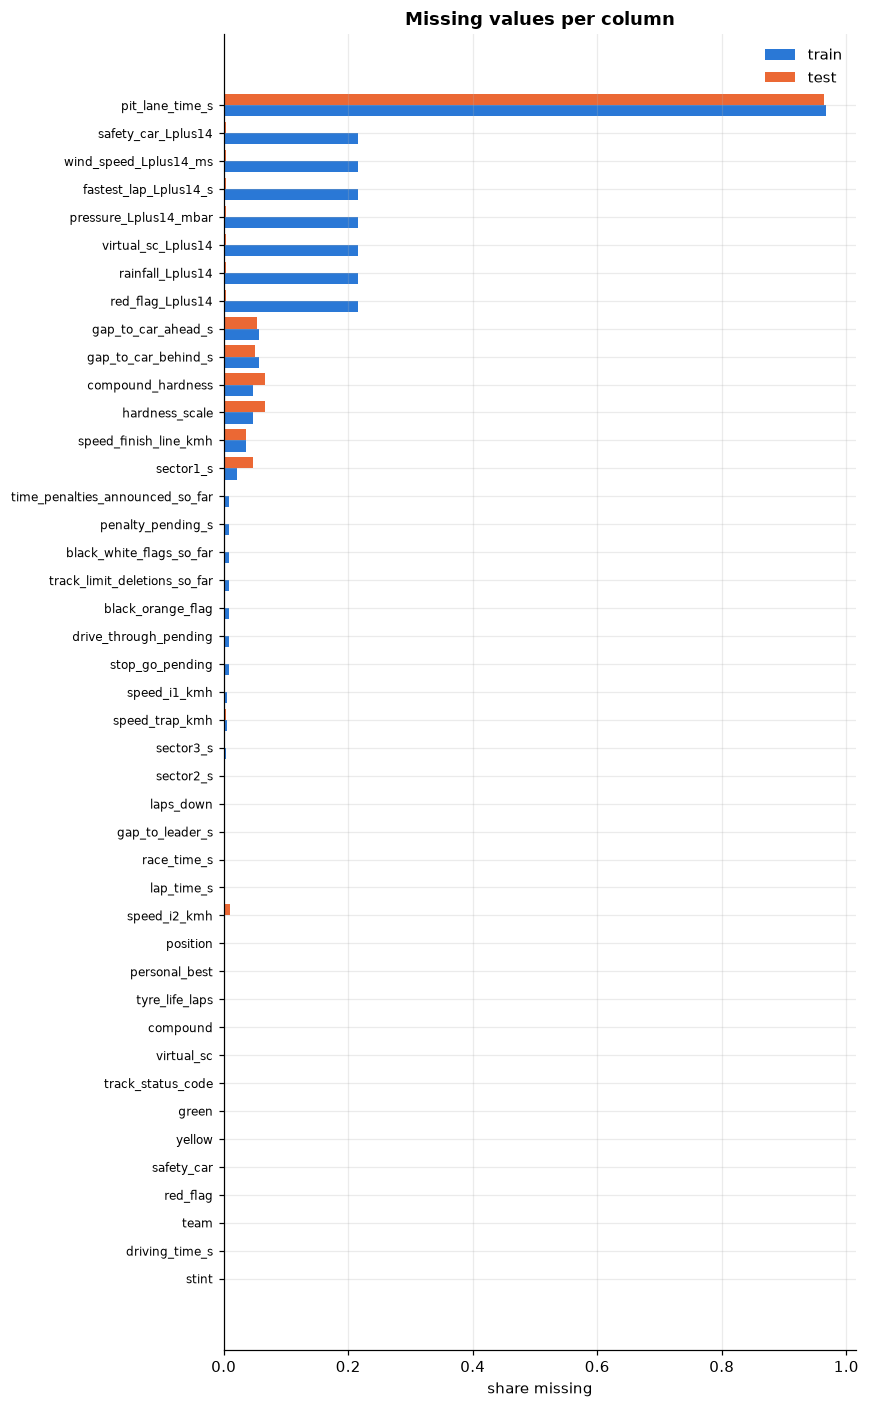

  saved eda_plots/10_missing_values.png

Done. Charts are in /Users/edouarddewaerheijd/unige/Formula-1-Tyre-Strategy/eda_plots


In [11]:
section("9. Missing values")
miss = pd.DataFrame({"train": train.drop(columns=[TARGET]).isna().mean(),
                     "test": test.isna().mean()}).dropna()
miss = miss.loc[miss.max(axis=1) > 0].sort_values("train")
print(miss.round(3).to_string())
fig, ax = plt.subplots(figsize=(8, max(3, 0.3 * len(miss))))
y = np.arange(len(miss))
ax.barh(y - 0.2, miss["train"], height=0.4, label="train", color="#2a78d6")
ax.barh(y + 0.2, miss["test"], height=0.4, label="test", color="#eb6834")
ax.set_yticks(y, miss.index, fontsize=8)
ax.set_xlabel("share missing")
ax.set_title("Missing values per column")
ax.legend(frameon=False)
save(fig, "10_missing_values")

print(f"\nDone. Charts are in {OUT.resolve()}")

**Results.**
- Almost all columns are < 1% missing in both sets.
- `*_Lplus14` columns: **21.5% missing in train, 0.4% in test**. In train they are missing for the last 14 laps of a race (no "+14 laps" exists), which are almost all NONE → missingness itself leaks the label in train but is absent in test. Don't use a "is missing" indicator; restricting training to the test window removes the issue.
- `hardness_scale` / `compound_hardness`: ~5–7% missing in both — impute (e.g. per circuit/year) or let trees handle NaN.
- `pit_lane_time_s`: ~97% missing in both → encode as binary `pitted_this_lap`, don't impute.
- Gaps to car ahead/behind ~5–6% missing (leader / last car) → natural NaN, fill with a large value or a flag.